# 02 · Calentamiento: destilación de un MLP en MNIST

**Objetivo de este cuaderno:** ver la destilación de conocimiento en un problema pequeño y medible, de punta a punta. Se entrena un **profesor** MLP, se entrena un **estudiante** mucho más pequeño con etiquetas duras y se entrena *el mismo* estudiante copiando las etiquetas blandas del profesor. Al final se comparan exactitud, tamaño y latencia, y se guardan artefactos para el cuaderno 04.

MNIST no es un problema difícil: un MLP pequeño, con suficientes etiquetas duras, ya acierta mucho y la destilación apenas se nota. El experimento se diseña a propósito con **pocas etiquetas para el estudiante** (400 imágenes). Con tan pocos ejemplos, el estudiante duro tiende a memorizar el train; el destilado recibe, en cada imagen, una distribución rica del profesor (entrenado con 30 000) y suele generalizar mejor. Ese es un caso realista: el profesor se entrenó cuando había más datos o más cómputo; el estudiante tiene que arreglárselas con un subconjunto.

## Diseño del experimento

| Pieza | Qué es | Datos |
|---|---|---|
| Profesor | MLP `[784, 256, 128, 10]` | 30 000 imágenes de train |
| Estudiante duro | MLP `[784, 32, 10]`, solo etiquetas 0/1 | 400 imágenes de train |
| Estudiante destilado | La misma arquitectura y los mismos pesos iniciales, con \(T=4\), \(\alpha=0.5\) | Las mismas 400, más las blandas del profesor |
| Test | No se usa para elegir nada | 5 000 imágenes del test oficial |

Los dos estudiantes arrancan del **mismo estado inicial**. Si no, una diferencia de exactitud podría deberse a la suerte de la inicialización, no a la destilación.


In [1]:
from pathlib import Path
import os, sys, json, time, gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "destilacion_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de destilacion "
        "(src/destilacion_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from destilacion_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    softmax_temperatura,
    divergencia_kl,
    perdida_destilacion,
    construir_mlp,
    construir_estudiante_sentimiento,
    contar_parametros,
    tamano_archivo_mb,
    guardar_json,
    cargar_json,
    guardar_checkpoint,
    cargar_checkpoint,
    evaluar_loader,
    medir_latencia_ms,
    entrenar_epoca,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/destilacion/cache-hf
  Modo offline HF: False
  Ajustes aplicados en esta sesión:
    - HF_HUB_DISABLE_TELEMETRY=1
Raiz:        /workspace/destilacion
Dispositivo: cpu
Semilla:     42


## 1. Parámetros

Como en el resto del curso, los parámetros van al principio y no se editan a ciegas a mitad del cuaderno. Si quieres experimentar, cámbialos aquí y vuelve a ejecutar desde esta celda. El cuaderno 05 propone variaciones sistemáticas de \(T\) y \(\alpha\).


In [2]:
import torch
from torch import optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

N_TRAIN_PROFESOR = 30_000
N_TRAIN_ESTUDIANTE = 400
N_TEST = 5_000
EPOCHS_PROFESOR = 4
EPOCHS_ESTUDIANTE = 25
BATCH = 64
LR_PROFESOR = 1e-3
LR_ESTUDIANTE = 1e-3
ANCHOS_PROFESOR = [784, 256, 128, 10]
ANCHOS_ESTUDIANTE = [784, 32, 10]
T_DISTIL = 4.0
ALPHA = 0.5
DROP_PROFESOR = 0.2
DROP_ESTUDIANTE = 0.0

print("dispositivo:", DEVICE)
print("profesor:", ANCHOS_PROFESOR, "épocas", EPOCHS_PROFESOR, "datos", N_TRAIN_PROFESOR)
print("estudiante:", ANCHOS_ESTUDIANTE, "épocas", EPOCHS_ESTUDIANTE, "datos", N_TRAIN_ESTUDIANTE)
print(f"destilación: T={T_DISTIL}, alpha={ALPHA}")


dispositivo: cpu
profesor: [784, 256, 128, 10] épocas 4 datos 30000
estudiante: [784, 32, 10] épocas 25 datos 400
destilación: T=4.0, alpha=0.5


## 2. Datos

MNIST se descarga una vez a `datos/mnist/`. Las imágenes se normalizan con la media y la desviación habituales del conjunto y se aplanan a un vector de 784. Las particiones del estudiante son un **subconjunto** de las del profesor (mismas primeras 400, tras un barajado con la semilla del proyecto). Test no se mezcla con train.


train profesor=30000, train estudiante=400, test=5000 (MNIST train completo=60000, test completo=10000)


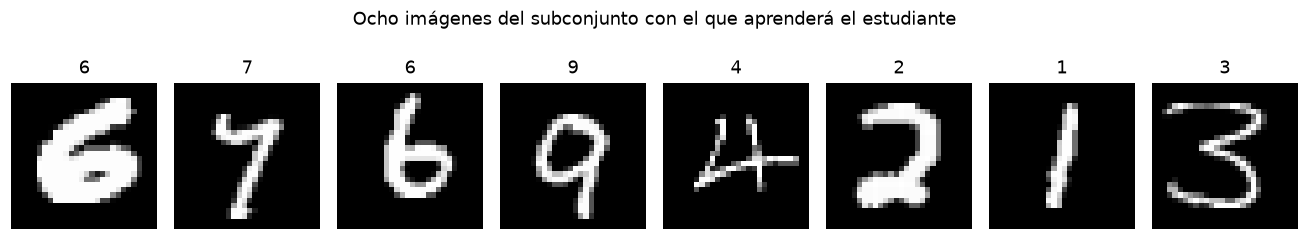

In [3]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)),
        transforms.Lambda(lambda t: t.reshape(-1)),
    ]
)

train_full = datasets.MNIST(RUTAS["datos"] / "mnist", train=True, download=True, transform=transform)
test_full = datasets.MNIST(RUTAS["datos"] / "mnist", train=False, download=True, transform=transform)

g = torch.Generator().manual_seed(SEMILLA)
idx_train = torch.randperm(len(train_full), generator=g).tolist()
idx_test = torch.randperm(len(test_full), generator=g).tolist()

ds_profesor = Subset(train_full, idx_train[:N_TRAIN_PROFESOR])
ds_estudiante = Subset(train_full, idx_train[:N_TRAIN_ESTUDIANTE])
ds_test = Subset(test_full, idx_test[:N_TEST])

# Para visualizar, una copia sin normalizar ni aplanar.
raw_train = datasets.MNIST(RUTAS["datos"] / "mnist", train=True, download=False, transform=transforms.ToTensor())


def hacer_loader(ds, shuffle, batch=BATCH):
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, num_workers=0)


loader_prof = hacer_loader(ds_profesor, shuffle=True)
loader_est = hacer_loader(ds_estudiante, shuffle=True)
loader_test = hacer_loader(ds_test, shuffle=False)

print(
    f"train profesor={len(ds_profesor)}, train estudiante={len(ds_estudiante)}, "
    f"test={len(ds_test)} (MNIST train completo={len(train_full)}, test completo={len(test_full)})"
)

# Un vistazo a dígitos del subconjunto del estudiante.
fig, ejes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(ejes, idx_train[:8]):
    img, y = raw_train[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(str(int(y)))
    ax.axis("off")
fig.suptitle("Ocho imágenes del subconjunto con el que aprenderá el estudiante", y=1.08)
fig.tight_layout()
plt.show()


## 3. Modelos: cuánto más pequeño es el estudiante


In [4]:
profesor = construir_mlp(ANCHOS_PROFESOR, dropout=DROP_PROFESOR).to(DEVICE)
estudiante_plantilla = construir_mlp(ANCHOS_ESTUDIANTE, dropout=DROP_ESTUDIANTE).to(DEVICE)

tabla_tam = pd.DataFrame(
    [
        {
            "modelo": "profesor",
            "anchos": str(ANCHOS_PROFESOR),
            "parametros": contar_parametros(profesor),
        },
        {
            "modelo": "estudiante",
            "anchos": str(ANCHOS_ESTUDIANTE),
            "parametros": contar_parametros(estudiante_plantilla),
        },
    ]
)
tabla_tam["ratio_respecto_profesor"] = tabla_tam["parametros"] / tabla_tam.loc[0, "parametros"]
display(tabla_tam)

n_prof = contar_parametros(profesor)
n_est = contar_parametros(estudiante_plantilla)
print(f"El estudiante tiene {n_est / n_prof:.1%} de los parámetros del profesor.")


,modelo,anchos,parametros,ratio_respecto_profesor
0,profesor,"[784, 256, 128, 10]",235146,1.000000
1,estudiante,"[784, 32, 10]",25450,0.108231


El estudiante tiene 10.8% de los parámetros del profesor.


## 4. Entrenar al profesor

El profesor se entrena de forma habitual: entropía cruzada con etiquetas duras, en las 30 000 imágenes. Después se deja en modo `eval` y ya no se mueve: es la fuente de las etiquetas blandas.


In [5]:
def entrenar(
    modelo,
    loader,
    epocas,
    lr,
    *,
    profesor_fijo=None,
    temperature=T_DISTIL,
    alpha=ALPHA,
    etiqueta="",
):
    opt = optim.Adam(modelo.parameters(), lr=lr)
    historial = []
    for epoca in range(1, epocas + 1):
        tr = entrenar_epoca(
            modelo,
            loader,
            opt,
            DEVICE,
            profesor=profesor_fijo,
            temperature=temperature,
            alpha=alpha if profesor_fijo is not None else 0.0,
        )
        ev = evaluar_loader(modelo, loader_test, DEVICE)
        fila = {
            "epoca": epoca,
            "train_perdida": tr["perdida"],
            "train_exactitud": tr["exactitud"],
            "test_exactitud": ev["exactitud"],
            "test_perdida": ev["perdida_ce"],
        }
        historial.append(fila)
        print(
            f"{etiqueta:22s} época {epoca:2d}/{epocas}  "
            f"train acc={tr['exactitud']:.3f}  test acc={ev['exactitud']:.3f}  "
            f"pérdida={tr['perdida']:.3f}"
        )
    return historial


hist_profesor = entrenar(
    profesor, loader_prof, EPOCHS_PROFESOR, LR_PROFESOR, etiqueta="profesor"
)
profesor.eval()
for p in profesor.parameters():
    p.requires_grad_(False)

metricas_profesor = evaluar_loader(profesor, loader_test, DEVICE)
print("profesor en test:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in metricas_profesor.items()})
assert metricas_profesor["exactitud"] > 0.90, (
    "El profesor debería superar el 90 % en test de MNIST. Revisa el entorno o aumenta las épocas."
)


profesor               época  1/4  train acc=0.886  test acc=0.951  pérdida=0.370


profesor               época  2/4  train acc=0.948  test acc=0.962  pérdida=0.170


profesor               época  3/4  train acc=0.961  test acc=0.961  pérdida=0.123


profesor               época  4/4  train acc=0.968  test acc=0.969  pérdida=0.101


profesor en test: {'exactitud': 0.9692, 'perdida_ce': 0.1, 'n': 5000}


## 5. Dos estudiantes, misma salida

Se clona el estado inicial. El primero ve solo etiquetas duras (`alpha = 0`, sin profesor). El segundo destila al profesor. Misma arquitectura, mismos datos, mismas épocas, mismo optimizador.


In [6]:
# Estado inicial común (la plantilla aún no se ha entrenado).
estado_inicial = {k: v.detach().cpu().clone() for k, v in estudiante_plantilla.state_dict().items()}

estudiante_duro = construir_mlp(ANCHOS_ESTUDIANTE, dropout=DROP_ESTUDIANTE).to(DEVICE)
estudiante_duro.load_state_dict(estado_inicial)
hist_duro = entrenar(
    estudiante_duro, loader_est, EPOCHS_ESTUDIANTE, LR_ESTUDIANTE, etiqueta="estudiante duro"
)

estudiante_kd = construir_mlp(ANCHOS_ESTUDIANTE, dropout=DROP_ESTUDIANTE).to(DEVICE)
estudiante_kd.load_state_dict(estado_inicial)
hist_kd = entrenar(
    estudiante_kd,
    loader_est,
    EPOCHS_ESTUDIANTE,
    LR_ESTUDIANTE,
    profesor_fijo=profesor,
    temperature=T_DISTIL,
    alpha=ALPHA,
    etiqueta="estudiante destilado",
)

metricas_duro = evaluar_loader(estudiante_duro, loader_test, DEVICE)
metricas_kd = evaluar_loader(estudiante_kd, loader_test, DEVICE)


estudiante duro        época  1/25  train acc=0.237  test acc=0.453  pérdida=2.145


estudiante duro        época  2/25  train acc=0.520  test acc=0.580  pérdida=1.660


estudiante duro        época  3/25  train acc=0.730  test acc=0.722  pérdida=1.281


estudiante duro        época  4/25  train acc=0.812  test acc=0.757  pérdida=0.990


estudiante duro        época  5/25  train acc=0.855  test acc=0.790  pérdida=0.773


estudiante duro        época  6/25  train acc=0.877  test acc=0.800  pérdida=0.627


... (40 outputs left out)

estudiante destilado   época 22/25  train acc=0.963  test acc=0.863  pérdida=0.923


estudiante destilado   época 23/25  train acc=0.963  test acc=0.861  pérdida=0.880


estudiante destilado   época 24/25  train acc=0.963  test acc=0.865  pérdida=0.841


estudiante destilado   época 25/25  train acc=0.968  test acc=0.864  pérdida=0.822


## 6. Curvas y comparación

En train, el estudiante duro puede llegar a acertar casi todo: con 400 ejemplos, memorizar es fácil. La cifra que importa está en **test**. El destilado suele quedar por encima del duro ahí, porque las blandas del profesor actúan como una señal más rica (y, de paso, como regularizador). Si en tu ejecución la diferencia fuera pequeña o del otro signo, no la fuerces: anótala y el cuaderno 05 pregunta cuándo merece la pena destilar.


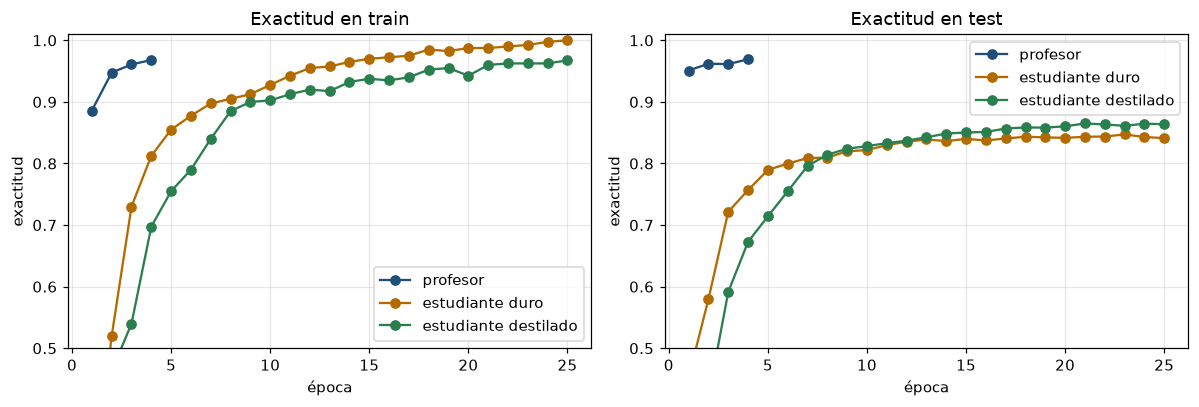

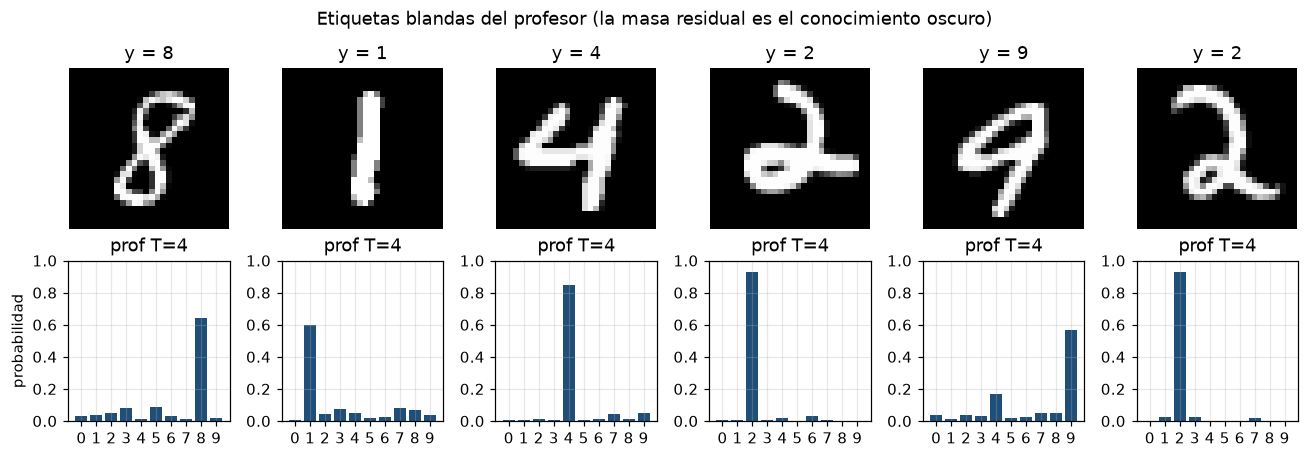

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for hist, nombre, color in [
    (hist_profesor, "profesor", "#1f4e79"),
    (hist_duro, "estudiante duro", "#b36b00"),
    (hist_kd, "estudiante destilado", "#2a7f4f"),
]:
    ep = [f["epoca"] for f in hist]
    ejes[0].plot(ep, [f["train_exactitud"] for f in hist], marker="o", label=nombre, color=color)
    ejes[1].plot(ep, [f["test_exactitud"] for f in hist], marker="o", label=nombre, color=color)
ejes[0].set_title("Exactitud en train")
ejes[1].set_title("Exactitud en test")
for ax in ejes:
    ax.set_xlabel("época")
    ax.set_ylabel("exactitud")
    ax.set_ylim(0.5, 1.01)
    ax.legend()
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_mnist_curvas.png", bbox_inches="tight")
plt.show()

# Un lote de test: el profesor "explica" un dígito a T=1 y a T=3.
estudiante_kd.eval()
x_vis, y_vis = next(iter(loader_test))
x_vis, y_vis = x_vis.to(DEVICE), y_vis.to(DEVICE)
with torch.no_grad():
    logits_p = profesor(x_vis[:6])

fig, ejes = plt.subplots(2, 6, figsize=(12, 4.2))
# Reconstruir una imagen aproximada deshaciendo la normalización solo para verla.
for i in range(6):
    img = x_vis[i].detach().cpu().reshape(28, 28) * 0.3081 + 0.1307
    ejes[0, i].imshow(img.numpy(), cmap="gray")
    ejes[0, i].set_title(f"y = {int(y_vis[i])}")
    ejes[0, i].axis("off")
    p3 = softmax_temperatura(logits_p[i].cpu().numpy(), temperature=T_DISTIL)
    ejes[1, i].bar(range(10), p3, color="#1f4e79")
    ejes[1, i].set_xticks(range(10))
    ejes[1, i].set_ylim(0, 1)
    ejes[1, i].set_title(f"prof T={int(T_DISTIL)}")
ejes[1, 0].set_ylabel("probabilidad")
fig.suptitle("Etiquetas blandas del profesor (la masa residual es el conocimiento oscuro)")
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_mnist_blandas.png", bbox_inches="tight")
plt.show()


## 7. Tamaño, latencia y artefactos

Se mide la latencia de un lote de 64 en el dispositivo actual (casi seguro CPU). El 04 volverá a leer estas cifras y, si los pesos siguen ahí, puede remedirlas.


In [8]:
lote_latencia = next(iter(loader_test))[0][:64].to(DEVICE)
lat_prof = medir_latencia_ms(profesor, lote_latencia, device=DEVICE)
lat_duro = medir_latencia_ms(estudiante_duro, lote_latencia, device=DEVICE)
lat_kd = medir_latencia_ms(estudiante_kd, lote_latencia, device=DEVICE)

ruta_prof = RUTAS["modelos"] / "mnist_profesor.pt"
ruta_duro = RUTAS["modelos"] / "mnist_estudiante_duro.pt"
ruta_kd = RUTAS["modelos"] / "mnist_estudiante_destilado.pt"

meta_base = {
    "anchos_profesor": ANCHOS_PROFESOR,
    "anchos_estudiante": ANCHOS_ESTUDIANTE,
    "n_train_profesor": N_TRAIN_PROFESOR,
    "n_train_estudiante": N_TRAIN_ESTUDIANTE,
    "n_test": N_TEST,
    "epochs_profesor": EPOCHS_PROFESOR,
    "epochs_estudiante": EPOCHS_ESTUDIANTE,
    "temperature": T_DISTIL,
    "alpha": ALPHA,
    "semilla": SEMILLA,
    "dispositivo": str(DEVICE),
    "dropout_profesor": DROP_PROFESOR,
    "dropout_estudiante": DROP_ESTUDIANTE,
}

guardar_checkpoint(profesor, ruta_prof, {**meta_base, "rol": "profesor", **metricas_profesor})
guardar_checkpoint(estudiante_duro, ruta_duro, {**meta_base, "rol": "estudiante_duro", **metricas_duro})
guardar_checkpoint(estudiante_kd, ruta_kd, {**meta_base, "rol": "estudiante_destilado", **metricas_kd})

resultado = {
    "problema": "mnist-mlp",
    "semilla": SEMILLA,
    "dispositivo": str(DEVICE),
    "temperature": T_DISTIL,
    "alpha": ALPHA,
    "dropout_profesor": DROP_PROFESOR,
    "dropout_estudiante": DROP_ESTUDIANTE,
    "n_train_profesor": N_TRAIN_PROFESOR,
    "n_train_estudiante": N_TRAIN_ESTUDIANTE,
    "n_test": N_TEST,
    "modelos": {
        "profesor": {
            "ruta": str(ruta_prof.relative_to(RAIZ)),
            "anchos": ANCHOS_PROFESOR,
            "parametros": contar_parametros(profesor),
            "tamano_mb": tamano_archivo_mb(ruta_prof),
            **metricas_profesor,
            **{f"latencia_{k}": v for k, v in lat_prof.items()},
        },
        "estudiante_duro": {
            "ruta": str(ruta_duro.relative_to(RAIZ)),
            "anchos": ANCHOS_ESTUDIANTE,
            "parametros": contar_parametros(estudiante_duro),
            "tamano_mb": tamano_archivo_mb(ruta_duro),
            **metricas_duro,
            **{f"latencia_{k}": v for k, v in lat_duro.items()},
        },
        "estudiante_destilado": {
            "ruta": str(ruta_kd.relative_to(RAIZ)),
            "anchos": ANCHOS_ESTUDIANTE,
            "parametros": contar_parametros(estudiante_kd),
            "tamano_mb": tamano_archivo_mb(ruta_kd),
            **metricas_kd,
            **{f"latencia_{k}": v for k, v in lat_kd.items()},
        },
    },
    "historial": {
        "profesor": hist_profesor,
        "estudiante_duro": hist_duro,
        "estudiante_destilado": hist_kd,
    },
}
guardar_json(resultado, RUTAS["resultados"] / "mnist.json")

comp = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "parametros": datos["parametros"],
            "tamano_mb": round(datos["tamano_mb"], 3),
            "exactitud_test": round(datos["exactitud"], 4),
            "ms_por_ejemplo": round(datos["latencia_ms_por_ejemplo_media"], 4),
        }
        for nombre, datos in resultado["modelos"].items()
    ]
)
display(comp)
print("Artefactos escritos en modelos/ y resultados/mnist.json")


,modelo,parametros,tamano_mb,exactitud_test,ms_por_ejemplo
0,profesor,235146,0.9,0.9692,0.0012
1,estudiante_duro,25450,0.1,0.8412,0.0004
2,estudiante_destilado,25450,0.1,0.8638,0.0004


Artefactos escritos en modelos/ y resultados/mnist.json


## Interpretación y cierre

- El profesor es la referencia de calidad. El estudiante destilado no tiene por qué igualarlo: tiene menos capacidad y dos órdenes de magnitud menos de datos. El éxito es **generalizar mejor que el estudiante duro** (mismo modelo, mismos 400 ejemplos, mismos pesos iniciales) y acercarse al profesor más de lo que las etiquetas duras solas permiten.
- La latencia, en un MLP de este tamaño, es muy baja en CPU. El contraste de coste se verá mejor en el cuaderno 03, con un DistilBERT de decenas de millones de parámetros frente a un GRU diminuto.
- Estos resultados son la entrada del cuaderno 04. No borres `modelos/` ni `resultados/mnist.json` si quieres la comparativa completa.

Siguiente: `03-destilacion-bert-sentimiento.ipynb`.
